
# Mobile Wallet Fraud Detection

 1. Problem Framing:

Mobile wallet services process a large number of transactions every day. Some of these transactions may be fraudulent, which can cause financial losses for payment providers and their customers.

The goal of this project is to build a Machine Learning model that identifies potentially fraudulent mobile wallet transactions and helps payment providers decide which transactions need further investigation.

 Stakeholders:

- Mobile wallet companies and payment providers.
- Fraud detection and risk management teams.
- Customers who need secure financial transactions.

Target Variable:

The target variable is `isFraud`:

- `0`: Legitimate transaction.
- `1`: Fraudulent transaction.

Model Decision:

The model predicts the probability that a transaction is fraudulent. Transactions with high fraud probabilities can be flagged for further review.

The model is designed as a decision-support tool, not as automatic proof of fraud.

 Business Metrics:

Because fraudulent transactions represent a very small part of the dataset, accuracy alone is not a reliable performance measure.

Average Precision is used to evaluate how well the model identifies fraudulent transactions while considering precision and recall.

Precision, Recall, and F1-score are also used to evaluate the model and select a decision threshold.

 2. Dataset Source:

This project uses the PaySim Synthetic Financial Datasets for Fraud Detection.

Source: https://www.kaggle.com/datasets/ealaxi/paysim1

The dataset contains simulated mobile money transactions and is used for fraud detection research.

The dataset is synthetic, so its results may not fully represent real-world mobile wallet transactions.


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, average_precision_score, precision_score, recall_score, f1_score, PrecisionRecallDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [13]:
dataset = pd.read_csv("fraud_datection_dataset.csv", low_memory=False)

print("Dataset source: PaySim synthetic mobile money transactions")
print("Dataset shape:", dataset.shape)
print("\nDataset information:")
dataset.info()
print("\nMissing values:")
print(dataset.isnull().sum())

dataset = dataset.dropna(subset=["isFraud"]).copy()
dataset["isFraud"] = dataset["isFraud"].astype("int8")

if dataset.empty:
    raise ValueError("The dataset is empty after removing rows with a missing target.")

if not set(dataset["isFraud"].unique()).issubset({0, 1}):
    raise ValueError("The target column must contain only 0 and 1.")

if dataset["isFraud"].nunique() != 2:
    raise ValueError("The target column must contain both legitimate and fraudulent transactions.")

if (dataset["amount"].dropna() < 0).any():
    raise ValueError("Negative transaction amounts were found. Review them before applying the log transformation.")

print("\nDataset shape after removing rows with missing target:", dataset.shape)

Dataset source: PaySim synthetic mobile money transactions
Dataset shape: (6362620, 11)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Dataset shape after removing rows with missing target: (6362620, 11)


In [14]:
print("\nTarget distribution:")
print(dataset["isFraud"].value_counts().sort_index())

print("\nTarget distribution percentage:")
print((dataset["isFraud"].value_counts(normalize=True).sort_index() * 100).round(4))

print("\nTransaction type distribution:")
print(dataset["type"].value_counts(dropna=False))

print("\nFraud distribution by transaction type:")
print(pd.crosstab(dataset["type"], dataset["isFraud"], margins=True, dropna=False))

print("\nTransaction amount statistics:")
print(dataset["amount"].describe())

print("\nTransaction amount statistics by fraud status:")
print(dataset.groupby("isFraud")["amount"].describe())

print("\nColumn dictionary:")
column_descriptions = {
    "step": "Time step of the transaction in the simulation",
    "type": "Type of mobile money transaction",
    "amount": "Transaction amount",
    "nameOrig": "Identifier of the account sending the transaction",
    "oldbalanceOrg": "Sender account balance before the transaction",
    "newbalanceOrig": "Sender account balance after the transaction",
    "nameDest": "Identifier of the account receiving the transaction",
    "oldbalanceDest": "Recipient account balance before the transaction",
    "newbalanceDest": "Recipient account balance after the transaction",
    "isFraud": "Target label: 1 for fraudulent and 0 for legitimate",
    "isFlaggedFraud": "Flag indicating whether the transaction was flagged by the original system"
}

data_dictionary = pd.DataFrame({
    "Column": dataset.columns,
    "Description": [column_descriptions.get(column, "Description not provided") for column in dataset.columns],
    "Data Type": [str(dataset[column].dtype) for column in dataset.columns]
})
print(data_dictionary.to_string(index=False))

print("\nFeatures selected for machine learning:")
print(["step", "amount", "type"])

print("\nColumns excluded from the model:")
print([column for column in dataset.columns if column not in ["step", "amount", "type", "isFraud"]])


Target distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Target distribution percentage:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

Transaction type distribution:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Fraud distribution by transaction type:
isFraud         0     1      All
type                            
CASH_IN   1399284     0  1399284
CASH_OUT  2233384  4116  2237500
DEBIT       41432     0    41432
PAYMENT   2151495     0  2151495
TRANSFER   528812  4097   532909
All       6354407  8213  6362620

Transaction amount statistics:
count    6.362620e+06
mean     1.798619e+05
std      6.038582e+05
min      0.000000e+00
25%      1.338957e+04
50%      7.487194e+04
75%      2.087215e+05
max      9.244552e+07
Name: amount, dtype: float64

Transaction amount statistics by fraud status:
             count          mean           std   min         25% 


## EDA Insights

The exploratory data analysis revealed several important patterns in the PaySim dataset:

1. **Severe Class Imbalance:** Fraudulent transactions represent only 0.1291% of the dataset, while legitimate transactions represent 99.8709%. This makes fraud detection a highly imbalanced classification problem, where accuracy alone is not a reliable evaluation metric.

2. **Transaction Type and Fraud:** TRANSFER transactions have the highest observed fraud rate at 0.7685%, followed by CASH_OUT transactions at 0.1840%. No fraudulent transactions were observed in the other transaction types in this dataset.

3. **Transaction Amount Differences:** The average fraudulent transaction amount is approximately 1,484,808.69, compared with 178,253.23 for legitimate transactions. This suggests that transaction amount may provide useful information for identifying suspicious activity.

4. **Amount Distribution and Outliers:** Transaction amounts have a highly skewed distribution, and approximately 5.31% of transactions exceed the upper IQR limit. These observations were retained because unusually large transactions may contain useful fraud-related information.

5. **Feature Selection:** Transaction type, amount, and step were selected as model features. Account identifiers were excluded because they mainly identify individual accounts rather than provide directly generalizable transaction patterns. Balance-related variables were also excluded from the current model to keep the feature set focused.

These findings guided the preprocessing, feature selection, model evaluation, and threshold selection stages of the project.


## Feature Selection

Three features were selected for the model:

- **step:** Represents the time step of the transaction.
- **amount:** Represents the transaction amount.
- **type:** Represents the transaction category.

The following columns were excluded:

- **nameOrig and nameDest:** Account identifiers with high cardinality.
- **Balance-related features:** Excluded from the current model to keep the feature set focused. They may be explored in future improvements.
- **isFlaggedFraud:** Excluded because it represents an existing fraud detection flag.

The selected features focus on transaction-level information. This is a modeling choice, and other features may improve performance in future experiments.

In [15]:
features = ["step", "amount", "type"]
target = "isFraud"

all_features = dataset[features].copy()
all_target = dataset[target].copy()

training_features, temporary_features, training_target, temporary_target = train_test_split(
    all_features,
    all_target,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=all_target
)

validation_features, test_features, validation_target, test_target = train_test_split(
    temporary_features,
    temporary_target,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temporary_target
)

del temporary_features, temporary_target, all_features, all_target

print("Training set shape:", training_features.shape)
print("Validation set shape:", validation_features.shape)
print("Final test set shape:", test_features.shape)

print("\nTraining target distribution percentage:")
print((training_target.value_counts(normalize=True).sort_index() * 100).round(4))

print("\nValidation target distribution percentage:")
print((validation_target.value_counts(normalize=True).sort_index() * 100).round(4))

print("\nFinal test target distribution percentage:")
print((test_target.value_counts(normalize=True).sort_index() * 100).round(4))

Training set shape: (4453834, 3)
Validation set shape: (954393, 3)
Final test set shape: (954393, 3)

Training target distribution percentage:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

Validation target distribution percentage:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

Final test target distribution percentage:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64


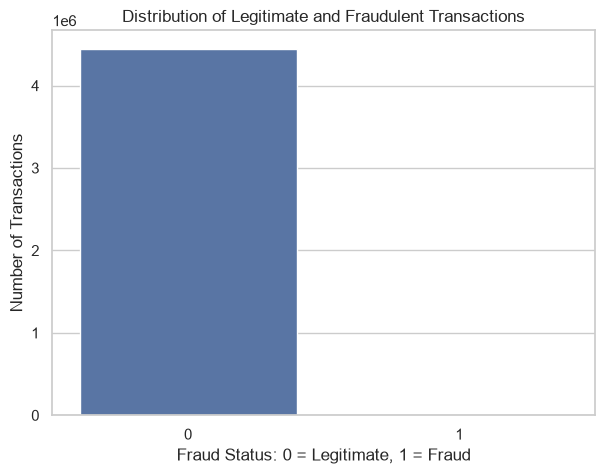

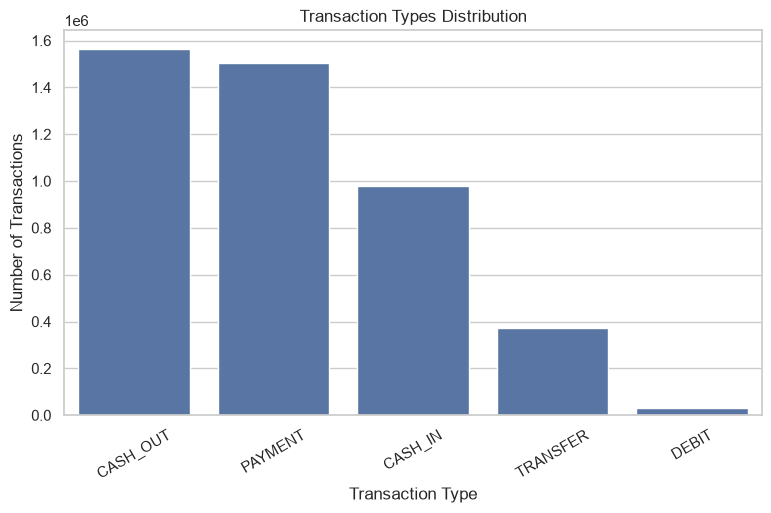

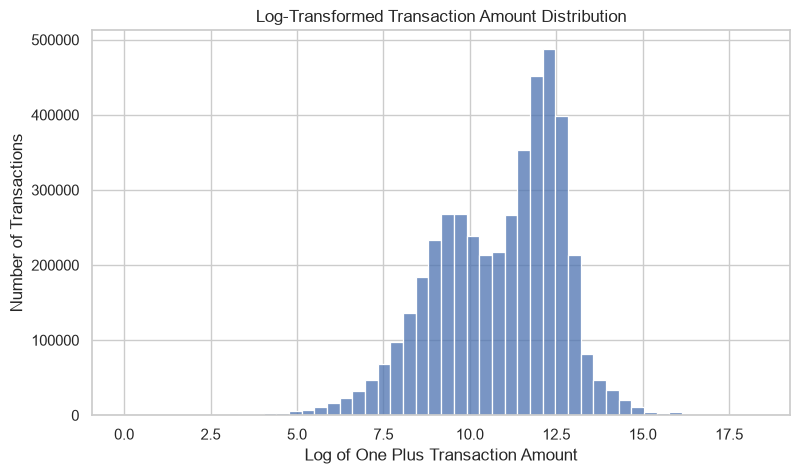

In [16]:
training_data = training_features.copy()
training_data[target] = training_target

plt.figure(figsize=(7, 5))
sns.countplot(data=training_data, x=target)
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Fraud Status: 0 = Legitimate, 1 = Fraud")
plt.ylabel("Number of Transactions")
plt.show()

plt.figure(figsize=(9, 5))
sns.countplot(data=training_data, x="type", order=training_data["type"].value_counts().index)
plt.title("Transaction Types Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(np.log1p(training_data["amount"].dropna()), bins=50)
plt.title("Log-Transformed Transaction Amount Distribution")
plt.xlabel("Log of One Plus Transaction Amount")
plt.ylabel("Number of Transactions")
plt.show()

Fraud rate by transaction type in the training set:
type
TRANSFER    0.7685
CASH_OUT    0.1840
CASH_IN     0.0000
DEBIT       0.0000
PAYMENT     0.0000
Name: isFraud, dtype: float64


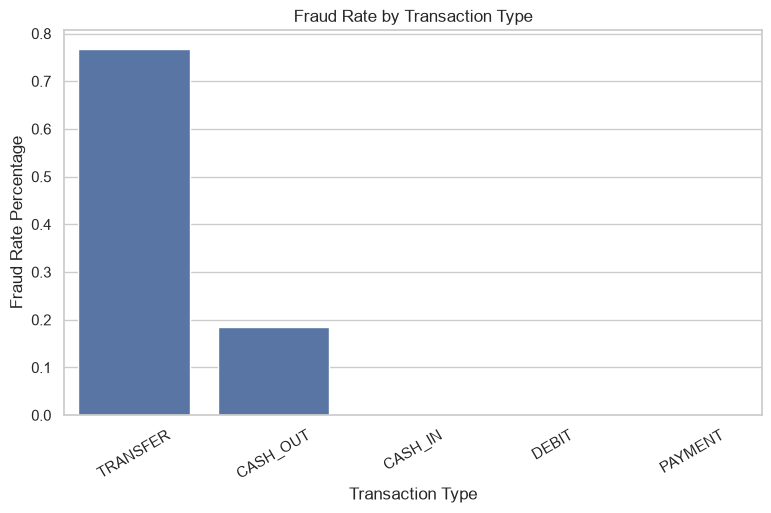

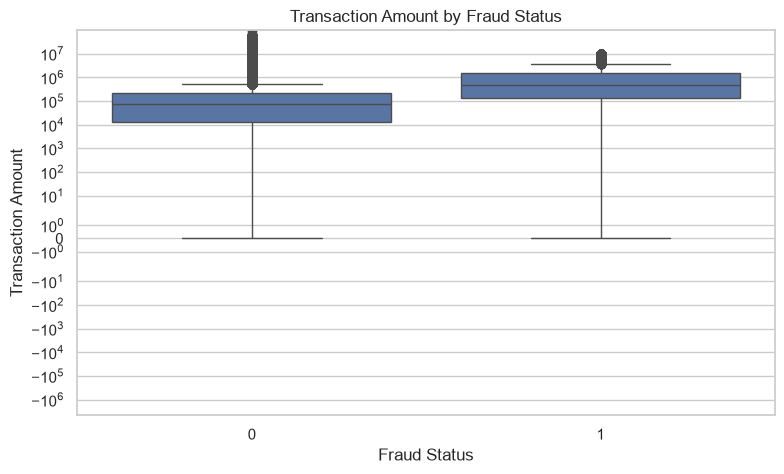

In [17]:
training_fraud_rate = (
    training_data.groupby("type", dropna=False)[target]
    .mean()
    .sort_values(ascending=False) * 100
)

print("Fraud rate by transaction type in the training set:")
print(training_fraud_rate.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(x=training_fraud_rate.index, y=training_fraud_rate.values)
plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate Percentage")
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=training_data, x=target, y="amount")
plt.yscale("symlog")
plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Fraud Status")
plt.ylabel("Transaction Amount")
plt.show()

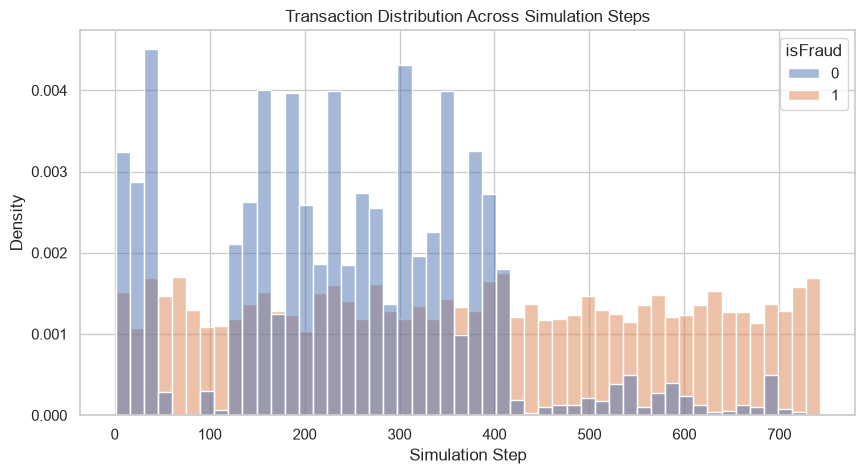

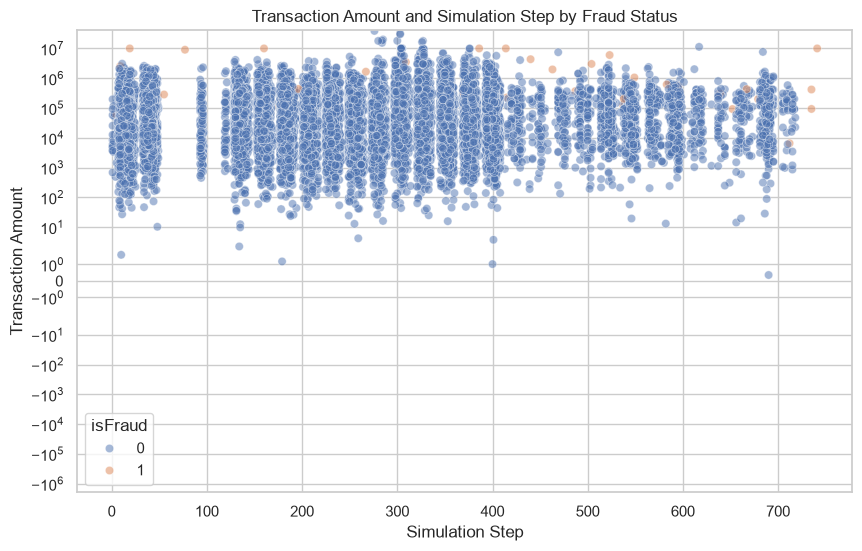

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=training_data,
    x="step",
    hue=target,
    bins=50,
    stat="density",
    common_norm=False
)
plt.title("Transaction Distribution Across Simulation Steps")
plt.xlabel("Simulation Step")
plt.ylabel("Density")
plt.show()

eda_sample = training_data.sample(
    n=min(30000, len(training_data)),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=eda_sample,
    x="step",
    y="amount",
    hue=target,
    alpha=0.5
)
plt.yscale("symlog")
plt.title("Transaction Amount and Simulation Step by Fraud Status")
plt.xlabel("Simulation Step")
plt.ylabel("Transaction Amount")
plt.show()

In [20]:
first_quartile = training_features["amount"].quantile(0.25)
third_quartile = training_features["amount"].quantile(0.75)
interquartile_range = third_quartile - first_quartile
upper_outlier_limit = third_quartile + 1.5 * interquartile_range

outlier_percentage = (
    (training_features["amount"] > upper_outlier_limit).mean() * 100
)

print(f"Percentage of amount values above the IQR upper limit: {outlier_percentage:.2f}%")
print("Amount outliers are retained because unusually large transactions may contain useful fraud-related information.")

Percentage of amount values above the IQR upper limit: 5.31%
Amount outliers are retained because unusually large transactions may contain useful fraud-related information.


In [21]:
step_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

amount_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

type_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("step", step_preprocessing, ["step"]),
        ("amount", amount_preprocessing, ["amount"]),
        ("type", type_preprocessing, ["type"])
    ],
    sparse_threshold=0.0
)

In [31]:

models = {
    "Majority Class Baseline": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=2
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=100,
        max_leaf_nodes=20,
        min_samples_leaf=20,
        random_state=RANDOM_STATE
    )
}


cross_validation_size = min(500000, len(training_features))

if cross_validation_size < len(training_features):
    cross_validation_features, _, cross_validation_target, _ = train_test_split(
        training_features,
        training_target,
        train_size=cross_validation_size,
        stratify=training_target,
        random_state=RANDOM_STATE
    )
else:
    cross_validation_features = training_features
    cross_validation_target = training_target

cross_validation = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

comparison_results = []

for model_name, classifier in models.items():
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    cross_validation_scores = cross_validate(
        model_pipeline,
        cross_validation_features,
        cross_validation_target,
        cv=cross_validation,
        scoring=["precision", "recall", "f1", "average_precision"],
        n_jobs=1
    )

    comparison_results.append({
        "Model": model_name,
        "Precision": cross_validation_scores["test_precision"].mean(),
        "Recall": cross_validation_scores["test_recall"].mean(),
        "F1 Score": cross_validation_scores["test_f1"].mean(),
        "Average Precision": cross_validation_scores["test_average_precision"].mean()
    })

model_comparison = pd.DataFrame(comparison_results)
print("Cross-validation model comparison:")
print(model_comparison.round(4).to_string(index=False))

Cross-validation model comparison:
                  Model  Precision  Recall  F1 Score  Average Precision
Majority Class Baseline     0.0000  0.0000    0.0000             0.0013
    Logistic Regression     0.0045  0.8713    0.0090             0.0390
          Decision Tree     0.0114  0.5488    0.0224             0.2235
          Random Forest     0.0334  0.5504    0.0630             0.2436
   HistGradientBoosting     0.1891  0.0946    0.1258             0.0939


In [23]:
random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=2
    ))
])

parameter_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [8, 10, 12],
    "classifier__min_samples_leaf": [5, 10, 20],
    "classifier__max_features": ["sqrt", 1.0]
}

randomized_search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=parameter_grid,
    n_iter=4,
    scoring="average_precision",
    cv=cross_validation,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True
)

randomized_search.fit(cross_validation_features, cross_validation_target)

print("Best hyperparameters:")
print(randomized_search.best_params_)
print("Best cross-validation Average Precision:", randomized_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best hyperparameters:
{'classifier__n_estimators': 50, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 12}
Best cross-validation Average Precision: 0.23577991539048693


In [24]:
best_pipeline = randomized_search.best_estimator_
best_pipeline.fit(training_features, training_target)

print("Final model training completed.")

Final model training completed.


Validation threshold comparison:
 Threshold  Precision  Recall  F1 Score  False Positives  Missed Fraud
      0.05     0.0029  1.0000    0.0058           422266             0
      0.10     0.0030  1.0000    0.0060           408255             0
      0.15     0.0032  0.9919    0.0064           379356            10
      0.20     0.0034  0.9854    0.0068           354859            18
      0.25     0.0049  0.9554    0.0098           238338            55
      0.30     0.0085  0.9058    0.0168           130905           116
      0.35     0.0098  0.8912    0.0194           110720           134
      0.40     0.0109  0.8734    0.0214            98076           156
      0.45     0.0117  0.8580    0.0231            89278           175
      0.50     0.0128  0.8401    0.0252            79991           197
      0.55     0.0140  0.8149    0.0275            70817           228
      0.60     0.0163  0.7857    0.0320            58393           264
      0.65     0.0228  0.7370    0.0442     

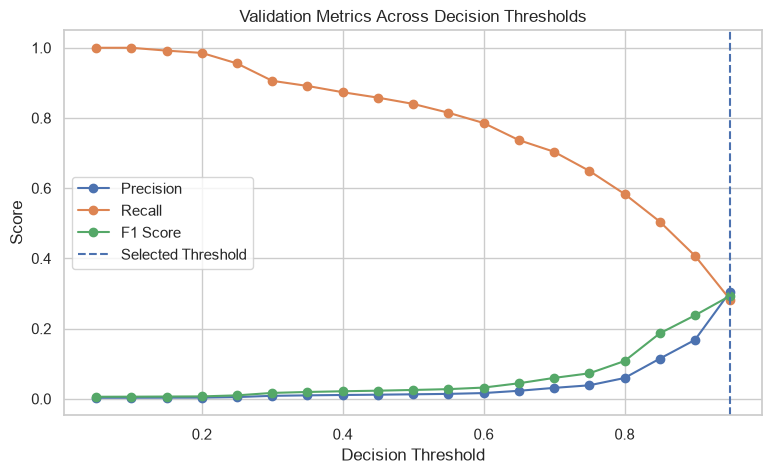

In [25]:
validation_probabilities = best_pipeline.predict_proba(validation_features)[:, 1]
threshold_values = np.arange(0.05, 1.00, 0.05)
threshold_results = []

for decision_threshold in threshold_values:
    validation_predictions = (validation_probabilities >= decision_threshold).astype(int)
    validation_confusion_matrix = confusion_matrix(
        validation_target,
        validation_predictions,
        labels=[0, 1]
    )

    threshold_results.append({
        "Threshold": decision_threshold,
        "Precision": precision_score(validation_target, validation_predictions, zero_division=0),
        "Recall": recall_score(validation_target, validation_predictions, zero_division=0),
        "F1 Score": f1_score(validation_target, validation_predictions, zero_division=0),
        "False Positives": validation_confusion_matrix[0, 1],
        "Missed Fraud": validation_confusion_matrix[1, 0]
    })

threshold_comparison = pd.DataFrame(threshold_results)
print("Validation threshold comparison:")
print(threshold_comparison.round(4).to_string(index=False))

selected_threshold_row = threshold_comparison.loc[threshold_comparison["F1 Score"].idxmax()]
final_threshold = float(selected_threshold_row["Threshold"])

print("Selected decision threshold:", final_threshold)
print("Validation precision:", selected_threshold_row["Precision"])
print("Validation recall:", selected_threshold_row["Recall"])
print("Validation F1 score:", selected_threshold_row["F1 Score"])

plt.figure(figsize=(9, 5))
plt.plot(threshold_comparison["Threshold"], threshold_comparison["Precision"], marker="o", label="Precision")
plt.plot(threshold_comparison["Threshold"], threshold_comparison["Recall"], marker="o", label="Recall")
plt.plot(threshold_comparison["Threshold"], threshold_comparison["F1 Score"], marker="o", label="F1 Score")
plt.axvline(final_threshold, linestyle="--", label="Selected Threshold")
plt.title("Validation Metrics Across Decision Thresholds")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.show()

Final test classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    953161
           1       0.30      0.28      0.29      1232

    accuracy                           1.00    954393
   macro avg       0.65      0.64      0.64    954393
weighted avg       1.00      1.00      1.00    954393

Final test Average Precision: 0.2676
Final test Precision: 0.3029
Final test Recall: 0.2752
Final test F1 Score: 0.2884
Final test confusion matrix:
[[952381    780]
 [   893    339]]


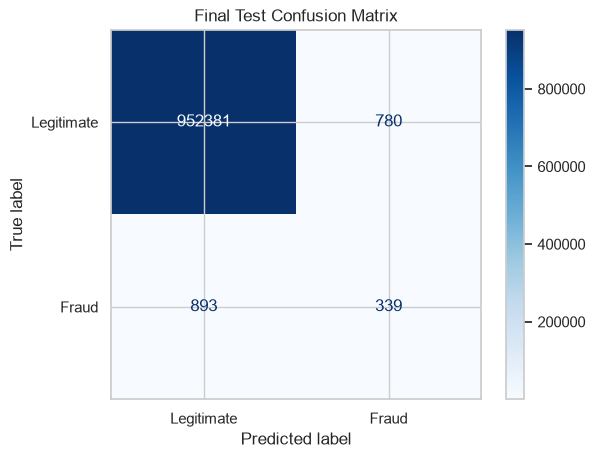

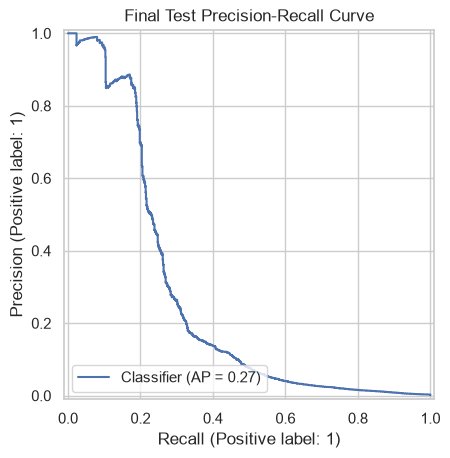

In [26]:
test_probabilities = best_pipeline.predict_proba(test_features)[:, 1]
test_predictions = (test_probabilities >= final_threshold).astype(int)

print("Final test classification report:")
print(classification_report(test_target, test_predictions, zero_division=0))

test_average_precision = average_precision_score(test_target, test_probabilities)
test_precision = precision_score(test_target, test_predictions, zero_division=0)
test_recall = recall_score(test_target, test_predictions, zero_division=0)
test_f1 = f1_score(test_target, test_predictions, zero_division=0)

print("Final test Average Precision:", round(test_average_precision, 4))
print("Final test Precision:", round(test_precision, 4))
print("Final test Recall:", round(test_recall, 4))
print("Final test F1 Score:", round(test_f1, 4))

test_confusion_matrix = confusion_matrix(test_target, test_predictions, labels=[0, 1])
print("Final test confusion matrix:")
print(test_confusion_matrix)

ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=["Legitimate", "Fraud"]
).plot(cmap="Blues")
plt.title("Final Test Confusion Matrix")
plt.show()

PrecisionRecallDisplay.from_predictions(test_target, test_probabilities)
plt.title("Final Test Precision-Recall Curve")
plt.show()

Feature importance:
            Feature  Importance
     amount__amount    0.289341
         step__step    0.257892
type__type_TRANSFER    0.201698
 type__type_PAYMENT    0.103274
 type__type_CASH_IN    0.080429
type__type_CASH_OUT    0.066005
   type__type_DEBIT    0.001360


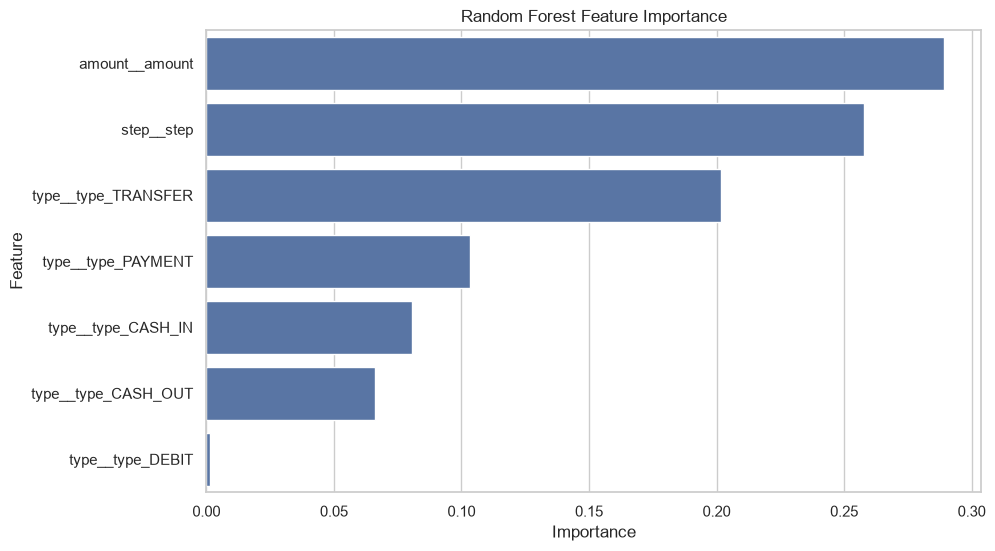

In [27]:
final_random_forest = best_pipeline.named_steps["classifier"]
transformed_feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": final_random_forest.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Feature importance:")
print(feature_importance.to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [28]:
training_fraud_count = int(training_target.sum())
training_legitimate_count = int((training_target == 0).sum())
training_fraud_percentage = training_target.mean() * 100

training_fraud_average_amount = training_features.loc[training_target == 1, "amount"].mean()
training_legitimate_average_amount = training_features.loc[training_target == 0, "amount"].mean()

print("Business insights from the training data:")
print(f"Fraudulent transactions represent {training_fraud_percentage:.4f}% of the training data.")
print(f"The training data contains {training_fraud_count:,} fraudulent transactions.")
print(f"The training data contains {training_legitimate_count:,} legitimate transactions.")

if not training_fraud_rate.empty:
    print(
        f"The transaction type with the highest observed fraud rate is "
        f"{training_fraud_rate.index[0]} ({training_fraud_rate.iloc[0]:.4f}%)."
    )

print(f"Average fraudulent transaction amount: {training_fraud_average_amount:,.2f}")
print(f"Average legitimate transaction amount: {training_legitimate_average_amount:,.2f}")

print("Business recommendations:")
print("Use the model to flag potentially suspicious transactions for further review.")
print("Use human review before blocking transactions based only on a model prediction.")
print("Monitor false positives because they may affect legitimate customers.")
print("Review the decision threshold using the financial cost of missed fraud and false alarms.")

print("Project limitations:")
print("PaySim is a synthetic dataset and may not represent all real-world mobile wallet behaviors.")
print("Model performance may change when the model is applied to real transaction data.")
print("Predictions are risk indicators and are not confirmation of fraud.")
print("The selected threshold maximizes validation F1 and is not based on a measured financial cost matrix.")

Business insights from the training data:
Fraudulent transactions represent 0.1291% of the training data.
The training data contains 5,749 fraudulent transactions.
The training data contains 4,448,085 legitimate transactions.
The transaction type with the highest observed fraud rate is TRANSFER (0.7685%).
Average fraudulent transaction amount: 1,484,808.69
Average legitimate transaction amount: 178,253.23
Business recommendations:
Use the model to flag potentially suspicious transactions for further review.
Use human review before blocking transactions based only on a model prediction.
Monitor false positives because they may affect legitimate customers.
Review the decision threshold using the financial cost of missed fraud and false alarms.
Project limitations:
PaySim is a synthetic dataset and may not represent all real-world mobile wallet behaviors.
Model performance may change when the model is applied to real transaction data.
Predictions are risk indicators and are not confirmati

In [29]:
model_package = {
    "model": best_pipeline,
    "pipeline": best_pipeline,
    "threshold": final_threshold,
    "features": ["step", "amount", "type"],
    "target": "isFraud"
}

joblib.dump(model_package, "fraud_detection_model.joblib")

saved_model_package = joblib.load("fraud_detection_model.joblib")

print("Final pipeline saved successfully.")
print("Saved model package keys:", saved_model_package.keys())
print("Saved decision threshold:", saved_model_package["threshold"])
print("The machine learning workflow is complete.")

Final pipeline saved successfully.
Saved model package keys: dict_keys(['model', 'pipeline', 'threshold', 'features', 'target'])
Saved decision threshold: 0.9500000000000001
The machine learning workflow is complete.


In [32]:
print("AVAILABLE RESULTS")
print("-----------------")

names = [
    "rf_tuning",
    "best_pipeline",
    "threshold_df",
    "final_threshold",
    "y_val_prob",
    "y_test_prob",
    "y_test_pred",
    "test_cm"
]

for name in names:
    print(name, "✓" if name in globals() else "✗")

if "rf_tuning" in globals():
    try:
        print("\nBest Parameters:")
        print(rf_tuning.best_params_)
        print("\nBest CV Score:")
        print(rf_tuning.best_score_)
    except Exception as e:
        print("Tuning results unavailable:", e)

if "threshold_df" in globals():
    print("\nThreshold Results:")
    display(threshold_df)

if "final_threshold" in globals():
    print("\nSelected Threshold:", final_threshold)

if "y_test_pred" in globals() and "y_test" in globals():
    from sklearn.metrics import classification_report, confusion_matrix

    print("\nFinal Test Report:")
    print(classification_report(y_test, y_test_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_test_pred))

AVAILABLE RESULTS
-----------------
rf_tuning ✗
best_pipeline ✓
threshold_df ✗
final_threshold ✓
y_val_prob ✓
y_test_prob ✗
y_test_pred ✗
test_cm ✗

Selected Threshold: 0.9500000000000001


In [33]:

print("Best Model Parameters:")

classifier = best_pipeline.named_steps["classifier"]

for parameter in [
    "n_estimators",
    "max_depth",
    "min_samples_leaf",
    "max_features",
    "class_weight"
]:
    print(parameter, ":", classifier.get_params().get(parameter))

if "y_val" in globals() and "y_val_prob" in globals():

    thresholds = np.round(np.arange(0.05, 1.00, 0.05), 2)
    results = []

    for threshold in thresholds:
        predictions = (y_val_prob >= threshold).astype(int)
        cm = confusion_matrix(y_val, predictions, labels=[0, 1])

        results.append({
            "Threshold": threshold,
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0),
            "False Positives": cm[0, 1],
            "Missed Fraud": cm[1, 0]
        })

    threshold_df = pd.DataFrame(results)

    print("\nValidation Threshold Results:")
    display(threshold_df)

    print("\nSelected Threshold:", round(final_threshold, 2))

else:
    print("\nValidation labels or probabilities are missing.")

if "X_test" in globals() and "y_test" in globals():

    probability_parts = []

    for start in range(0, len(X_test), 50000):
        batch = X_test.iloc[start:start + 50000]
        probability_parts.append(
            best_pipeline.predict_proba(batch)[:, 1]
        )

    y_test_prob = np.concatenate(probability_parts)
    y_test_pred = (y_test_prob >= final_threshold).astype(int)

    print("\nFINAL TEST CLASSIFICATION REPORT:")
    print(classification_report(y_test, y_test_pred, zero_division=0))

    test_cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

    print("\nConfusion Matrix:")
    print(test_cm)

    print("\nAverage Precision:", average_precision_score(y_test, y_test_prob))

else:
    print("\nTest data is missing.")


Best Model Parameters:
n_estimators : 50
max_depth : 12
min_samples_leaf : 10
max_features : sqrt
class_weight : balanced_subsample

Validation Threshold Results:


,Threshold,Precision,Recall,F1,False Positives,Missed Fraud
0,0.05,0.003422,0.984496,0.006820,36987,2
1,0.10,0.004040,0.937984,0.008046,29828,8
2,0.15,0.006059,0.891473,0.012036,18866,14
3,0.20,0.009949,0.829457,0.019662,10648,22
4,0.25,0.013769,0.767442,0.027053,7091,30
5,0.30,0.016874,0.736434,0.032992,5535,34
6,0.35,0.020814,0.682171,0.040395,4140,41
7,0.40,0.026248,0.635659,0.050415,3042,47
8,0.45,0.033812,0.620155,0.064128,2286,49
9,0.50,0.043300,0.573643,0.080522,1635,55



Selected Threshold: 0.95

Test data is missing.


In [34]:
variables = [
    "df",
    "X",
    "y",
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "X_test",
    "y_test",
    "X_test_final",
    "y_test_final"
]

for name in variables:
    obj = globals().get(name)

    if obj is None:
        print(name, "NOT FOUND")
    elif hasattr(obj, "shape"):
        print(name, obj.shape)
    else:
        print(name, "EXISTS")

df (6362620, 4)
X NOT FOUND
y NOT FOUND
X_train NOT FOUND
y_train NOT FOUND
X_val (100000, 3)
y_val (100000,)
X_test NOT FOUND
y_test NOT FOUND
X_test_final NOT FOUND
y_test_final NOT FOUND


In [35]:

features = ["step", "amount", "type"]
target = "isFraud"

all_indices = np.arange(len(df))
target_values = df[target].to_numpy()

train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=42,
    stratify=target_values
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=target_values[temp_indices]
)

X_test = df.iloc[test_indices][features].copy()
y_test = target_values[test_indices]

test_probabilities = np.empty(len(X_test), dtype=np.float32)

for start in range(0, len(X_test), 50000):
    end = min(start + 50000, len(X_test))

    test_probabilities[start:end] = (
        best_pipeline.predict_proba(
            X_test.iloc[start:end]
        )[:, 1]
    )

y_test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

error_data = X_test.copy()
error_data["Actual"] = y_test
error_data["Predicted"] = y_test_predictions
error_data["Fraud Probability"] = test_probabilities

false_positives = error_data[
    (error_data["Actual"] == 0) &
    (error_data["Predicted"] == 1)
]

missed_fraud = error_data[
    (error_data["Actual"] == 1) &
    (error_data["Predicted"] == 0)
]

print("False Positives:", len(false_positives))
print("Missed Fraud:", len(missed_fraud))

print("\nFalse Positives by Transaction Type:")
print(
    false_positives["type"].value_counts(normalize=True) * 100
)

print("\nMissed Fraud by Transaction Type:")
print(
    missed_fraud["type"].value_counts(normalize=True) * 100
)

print("\nFalse Positive Amount Statistics:")
print(false_positives["amount"].describe())

print("\nMissed Fraud Amount Statistics:")
print(missed_fraud["amount"].describe())


False Positives: 780
Missed Fraud: 893

False Positives by Transaction Type:
type
TRANSFER    93.333333
CASH_OUT     6.666667
CASH_IN      0.000000
DEBIT        0.000000
PAYMENT      0.000000
Name: proportion, dtype: float64

Missed Fraud by Transaction Type:
type
TRANSFER    53.639418
CASH_OUT    46.360582
CASH_IN      0.000000
DEBIT        0.000000
PAYMENT      0.000000
Name: proportion, dtype: float64

False Positive Amount Statistics:
count    7.800000e+02
mean     6.292898e+05
std      9.820225e+05
min      2.309350e+03
25%      1.063386e+05
50%      2.231416e+05
75%      9.716678e+05
max      9.952652e+06
Name: amount, dtype: float64

Missed Fraud Amount Statistics:
count    8.930000e+02
mean     6.629312e+05
std      1.199827e+06
min      0.000000e+00
25%      7.573499e+04
50%      2.549474e+05
75%      6.279031e+05
max      1.000000e+07
Name: amount, dtype: float64



## Error Analysis

The final model produced 780 False Positives and 893 False Negatives on the test set.

### False Positives

False Positives are legitimate transactions incorrectly classified as fraudulent.

- 93.33% of False Positives were TRANSFER transactions.
- 6.67% were CASH_OUT transactions.
- The average transaction amount was approximately 629,290.

These errors may lead to unnecessary transaction reviews and inconvenience for legitimate customers.

### False Negatives

False Negatives are fraudulent transactions incorrectly classified as legitimate.

- 53.64% of missed fraudulent transactions were TRANSFER transactions.
- 46.36% were CASH_OUT transactions.
- The average transaction amount was approximately 662,931.

These errors represent potentially fraudulent transactions that the model failed to identify.

### Error Analysis Conclusion

Most False Positives occurred in TRANSFER transactions, while missed fraud cases were distributed across both TRANSFER and CASH_OUT transactions.

The results show that the model still misses a considerable number of fraudulent transactions. Therefore, it should support fraud investigation rather than make automatic blocking decisions.
